# HVAC Association Graph


## Objective
Build an association graph for the HVAC system using NetworkX.

### Main tasks
1. Understand the HVAC dataset.
2. Identify sensor variables and derived metrics.
3. Define physical, thermodynamic, and control relationships.
4. Build an undirected graph.
5. Implement k-hop neighbourhood.
6. Implement allowed pairs.
7. Integrate graph constraints into Apriori.
8. Test and visualize the graph.

# Import Libraries 

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


# Locate the Project

In [3]:
ROOT = Path.cwd()

print("Project location:", ROOT)

print("\nProject folders:")
for item in ROOT.iterdir():
    print(item.name)

Project location: c:\Users\Asus\Desktop\gc-arm-llm-hvac\notebooks

Project folders:
01_explore.ipynb
02_llm_test.ipynb
03_vac_graph_learning.ipynb


# Read the actual dataset notes

In [5]:
from pathlib import Path

# Get the current notebook working directory
ROOT = Path.cwd()

# Move one level up if the notebook is inside notebooks/
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

print("Project root:", ROOT)

# Locate dataset documentation
notes_path = ROOT / "data" / "dataset_notes.md"

print("Notes file exists:", notes_path.exists())

# Read the documentation
if notes_path.exists():
    notes = notes_path.read_text(encoding="utf-8")
    print(notes)
else:
    print("File not found. Files inside data/:")
    print(list((ROOT / "data").iterdir()))

Project root: c:\Users\Asus\Desktop\gc-arm-llm-hvac
Notes file exists: True
# Dataset notes: LBNL simulated chiller plant

Status: confirmed against the official documentation `LBNL_FDD_Data_Sets_Chiller_Plant.pdf` (LBNL/PNNL, 1 Sept 2022).

## Source

Lawrence Berkeley National Laboratory (LBNL) Fault Detection and Diagnostics Data Sets, chiller plant.
Download: https://faultdetection.lbl.gov/dataset/simulated-chiller-plant/ ("Download all", 1.14 GB zip).
Cite (dataset): Lawrence Berkeley National Laboratory, LBNL FDD Data Sets. DOI: 10.25984/1881324
Cite (paper): J. Granderson et al., "A labeled dataset for building HVAC systems operating in faulted and
fault-free states," Scientific Data, vol. 10, 342, 2023. doi:10.1038/s41597-023-02197-w

Generated by simulation (EnergyPlus + Modelica) of a chiller plant serving a 12-floor large office
building (one AHU per floor). Weather: TMY data for Chicago, IL.

## System

- 3 identical chillers. Each has one dedicated primary chilled-water pu

# 1. HVAC System Architecture

## Main equipment
- 3 chillers
- 3 cooling towers
- 3 primary chilled-water pumps
- 3 condenser-water pumps
- 2 secondary chilled-water pumps

## Water circuits

### Primary chilled-water loop
- One dedicated constant-speed pump per chiller.
- The three primary loops combine and feed the secondary loop.

### Secondary chilled-water loop
- Two variable-speed pumps.
- A bypass line balances primary and secondary flow.
- Pump speed maintains differential pressure.

### Condenser-water loop
- Three condenser loops combine and feed three cooling towers.
- A three-way valve allows water to bypass the towers.

## Outdoor temperature controls
- OA_TEMP controls chilled-water supply setpoint reset.
- OA_TEMP_WB influences condenser-water supply setpoint.

## Important research observation
Outdoor temperature influences multiple HVAC variables through
the control system. This can create confounding in association
rule mining.

# 3. Association Graph Construction

## Step 1: Node Inventory

The association graph contains:
- Dataset variables (sensors, controls and environment).
- Derived energy-efficiency metrics.

We first identify every node before defining relationships.

In [6]:

# Chiller variables: 9 variables per chiller
chiller_variables = []

for i in range(1, 4):
    chiller_variables += [
        f"CHL_POW_{i}",
        f"CHL_SW_TEMP_{i}",
        f"CHL_RW_TEMP_{i}",
        f"CHL_CW_FLOW_{i}",
        f"CHL_SWCD_TEMP_{i}",
        f"CHL_RWCD_TEMP_{i}",
        f"CHL_CD_FLOW_{i}",
        f"CHL_COMP_SPD_CTRL_{i}",
        f"CHL_STA_{i}"
    ]


# Cooling tower variables: 7 per tower + 1 shared setpoint
cooling_tower_variables = []

for i in range(1, 4):
    cooling_tower_variables += [
        f"CT_POW_{i}",
        f"CT_FAN_SPD_{i}",
        f"CT_FLOW_{i}",
        f"CT_SW_TEMP_{i}",
        f"CT_RW_TEMP_{i}",
        f"CT_FAN_SPD_CTRL_{i}",
        f"CT_STA_{i}"
    ]

cooling_tower_variables.append("CT_SW_TEMPSPT")


# Condenser water loop
condenser_variables = [
    "CDWL_CW_FLOW",
    "CDWL_SW_TEMP",
    "CDWL_RW_TEMP"
] + [
    f"CDWL_PM_POW_{i}" for i in range(1, 4)
]


# Primary chilled-water loop
primary_variables = [
    "CWL_PRI_CW_FLOW",
    "CWL_PRI_SW_TEMP",
    "CWL_PRI_RW_TEMP"
] + [
    f"CWL_PRI_PM_POW_{i}" for i in range(1, 4)
] + ["CWL_PRI_SW_TEMPSPT"]


# Secondary chilled-water loop
secondary_variables = [
    "CWL_SEC_CW_FLOW",
    "CWL_SEC_SW_TEMP",
    "CWL_SEC_RW_TEMP",
    "CWL_SEC_DP",
    "CWL_SEC_LOAD"
] + [
    f"CWL_SEC_PM_POW_{i}" for i in range(1, 3)
] + [
    f"CWL_SEC_PM_SPD_{i}" for i in range(1, 3)
] + [
    "CWL_SEC_DPSPT",
    "CWL_SEC_PM_STA_1",
    "CWL_SEC_PM_STA_2"
]


# Valve and outdoor air
other_variables = [
    "TWV_CTRL",
    "OA_TEMP",
    "OA_TEMP_WB"
]


# Organize all variables
raw_groups = {
    "Chillers": chiller_variables,
    "Cooling Towers": cooling_tower_variables,
    "Condenser Loop": condenser_variables,
    "Primary Chilled Water": primary_variables,
    "Secondary Chilled Water": secondary_variables,
    "Valve and Outdoor Air": other_variables
}

raw_variables = [
    variable
    for group in raw_groups.values()
    for variable in group
]


# Display results
for group, variables in raw_groups.items():
    print(f"{group}: {len(variables)} variables")

print("-" * 40)
print("Total variables:", len(raw_variables))
print("Unique variables:", len(set(raw_variables)))


Chillers: 27 variables
Cooling Towers: 22 variables
Condenser Loop: 6 variables
Primary Chilled Water: 7 variables
Secondary Chilled Water: 12 variables
Valve and Outdoor Air: 3 variables
----------------------------------------
Total variables: 77
Unique variables: 77


# 4. Derived Metrics

Derived metrics are calculated from raw dataset variables.

Each derived metric will become a graph node.

The graph will connect each metric to its direct formula inputs
using thermodynamic edges.

In [7]:

# Dictionary: derived metric -> direct formula inputs

derived_metrics = {}

# 1. Chilled-water Delta T
for i in range(1, 4):
    derived_metrics[f"CHL_DT_{i}"] = [
        f"CHL_RW_TEMP_{i}",
        f"CHL_SW_TEMP_{i}"
    ]

# 2. Chiller cooling capacity
for i in range(1, 4):
    derived_metrics[f"CHL_CAP_TON_{i}"] = [
        f"CHL_CW_FLOW_{i}",
        f"CHL_DT_{i}"
    ]

# 3. Chiller COP
for i in range(1, 4):
    derived_metrics[f"CHL_COP_{i}"] = [
        f"CHL_CAP_TON_{i}",
        f"CHL_POW_{i}"
    ]

# 4. Plant total power
plant_power_inputs = (
    [f"CHL_POW_{i}" for i in range(1, 4)]
    + [f"CT_POW_{i}" for i in range(1, 4)]
    + [f"CDWL_PM_POW_{i}" for i in range(1, 4)]
    + [f"CWL_PRI_PM_POW_{i}" for i in range(1, 4)]
    + [f"CWL_SEC_PM_POW_{i}" for i in range(1, 3)]
)

derived_metrics["PLANT_TOTAL_POWER"] = plant_power_inputs

# 5. Plant COP
derived_metrics["PLANT_COP"] = [
    "CWL_SEC_LOAD",
    "PLANT_TOTAL_POWER"
]

# 6. Cooling tower approach
for i in range(1, 4):
    derived_metrics[f"CT_APPROACH_{i}"] = [
        f"CT_SW_TEMP_{i}",
        "OA_TEMP_WB"
    ]

# 7. Condenser-water Delta T
for i in range(1, 4):
    derived_metrics[f"CHL_CD_DT_{i}"] = [
        f"CHL_SWCD_TEMP_{i}",
        f"CHL_RWCD_TEMP_{i}"
    ]


# Extract the derived node names
derived_nodes = list(derived_metrics.keys())

# Validate the inventory
print("Number of derived metrics:", len(derived_nodes))
print("Unique derived metrics:", len(set(derived_nodes)))

print("\nDerived metrics and their inputs:")

for metric, inputs in derived_metrics.items():
    print(f"{metric} <- {inputs}")


Number of derived metrics: 17
Unique derived metrics: 17

Derived metrics and their inputs:
CHL_DT_1 <- ['CHL_RW_TEMP_1', 'CHL_SW_TEMP_1']
CHL_DT_2 <- ['CHL_RW_TEMP_2', 'CHL_SW_TEMP_2']
CHL_DT_3 <- ['CHL_RW_TEMP_3', 'CHL_SW_TEMP_3']
CHL_CAP_TON_1 <- ['CHL_CW_FLOW_1', 'CHL_DT_1']
CHL_CAP_TON_2 <- ['CHL_CW_FLOW_2', 'CHL_DT_2']
CHL_CAP_TON_3 <- ['CHL_CW_FLOW_3', 'CHL_DT_3']
CHL_COP_1 <- ['CHL_CAP_TON_1', 'CHL_POW_1']
CHL_COP_2 <- ['CHL_CAP_TON_2', 'CHL_POW_2']
CHL_COP_3 <- ['CHL_CAP_TON_3', 'CHL_POW_3']
PLANT_TOTAL_POWER <- ['CHL_POW_1', 'CHL_POW_2', 'CHL_POW_3', 'CT_POW_1', 'CT_POW_2', 'CT_POW_3', 'CDWL_PM_POW_1', 'CDWL_PM_POW_2', 'CDWL_PM_POW_3', 'CWL_PRI_PM_POW_1', 'CWL_PRI_PM_POW_2', 'CWL_PRI_PM_POW_3', 'CWL_SEC_PM_POW_1', 'CWL_SEC_PM_POW_2']
PLANT_COP <- ['CWL_SEC_LOAD', 'PLANT_TOTAL_POWER']
CT_APPROACH_1 <- ['CT_SW_TEMP_1', 'OA_TEMP_WB']
CT_APPROACH_2 <- ['CT_SW_TEMP_2', 'OA_TEMP_WB']
CT_APPROACH_3 <- ['CT_SW_TEMP_3', 'OA_TEMP_WB']
CHL_CD_DT_1 <- ['CHL_SWCD_TEMP_1', 'CHL_RWCD_TEMP_1

# Validate all dependencies

In [9]:
# Every input must be either a raw variable
# or another derived metric.

valid_nodes = set(raw_variables) | set(derived_nodes)

missing_inputs = {
    metric: [
        variable for variable in inputs
        if variable not in valid_nodes
    ]
    for metric, inputs in derived_metrics.items()
}

missing_inputs = {
    metric: missing
    for metric, missing in missing_inputs.items()
    if missing
}

print("Missing dependencies:", missing_inputs)
print("Total graph nodes:", len(raw_variables) + len(derived_nodes))

Missing dependencies: {}
Total graph nodes: 94


# 5. Edge Inventory

## 5.1 Physical Connections

Physical edges represent variables associated with
connected water circuits and equipment.

We represent these edges as undirected connections.

In [10]:

physical_edges = []

# A. Chillers <-> Primary chilled-water loop
for i in range(1, 4):
    physical_edges.extend([
        (f"CHL_SW_TEMP_{i}", "CWL_PRI_SW_TEMP"),
        (f"CHL_RW_TEMP_{i}", "CWL_PRI_RW_TEMP"),
        (f"CHL_CW_FLOW_{i}", "CWL_PRI_CW_FLOW"),
    ])

# B. Primary loop <-> Secondary loop
physical_edges.extend([
    ("CWL_PRI_SW_TEMP", "CWL_SEC_SW_TEMP"),
    ("CWL_PRI_RW_TEMP", "CWL_SEC_RW_TEMP"),
    ("CWL_PRI_CW_FLOW", "CWL_SEC_CW_FLOW"),
])

# C. Chillers <-> Condenser-water loop
for i in range(1, 4):
    physical_edges.extend([
        (f"CHL_SWCD_TEMP_{i}", "CDWL_RW_TEMP"),
        (f"CHL_RWCD_TEMP_{i}", "CDWL_SW_TEMP"),
        (f"CHL_CD_FLOW_{i}", "CDWL_CW_FLOW"),
    ])

# D. Cooling towers <-> Condenser-water loop
for i in range(1, 4):
    physical_edges.extend([
        (f"CT_SW_TEMP_{i}", "CDWL_SW_TEMP"),
        (f"CT_RW_TEMP_{i}", "CDWL_RW_TEMP"),
        (f"CT_FLOW_{i}", "CDWL_CW_FLOW"),
    ])

# Check that every endpoint exists
unknown_nodes = {
    node
    for edge in physical_edges
    for node in edge
    if node not in raw_variables
}

print("Physical edges:", len(physical_edges))
print("Unknown variables:", unknown_nodes)

print("\nFirst 10 physical edges:")
for edge in physical_edges[:10]:
    print(edge)


Physical edges: 30
Unknown variables: set()

First 10 physical edges:
('CHL_SW_TEMP_1', 'CWL_PRI_SW_TEMP')
('CHL_RW_TEMP_1', 'CWL_PRI_RW_TEMP')
('CHL_CW_FLOW_1', 'CWL_PRI_CW_FLOW')
('CHL_SW_TEMP_2', 'CWL_PRI_SW_TEMP')
('CHL_RW_TEMP_2', 'CWL_PRI_RW_TEMP')
('CHL_CW_FLOW_2', 'CWL_PRI_CW_FLOW')
('CHL_SW_TEMP_3', 'CWL_PRI_SW_TEMP')
('CHL_RW_TEMP_3', 'CWL_PRI_RW_TEMP')
('CHL_CW_FLOW_3', 'CWL_PRI_CW_FLOW')
('CWL_PRI_SW_TEMP', 'CWL_SEC_SW_TEMP')


In [11]:
thermodynamic_edges = []

for metric, inputs in derived_metrics.items():
    for input_var in inputs:
        thermodynamic_edges.append((input_var, metric))


# Validate that all edge endpoints exist
unknown_nodes = {
    node
    for edge in thermodynamic_edges
    for node in edge
    if node not in raw_variables and node not in derived_metrics
}

print("Thermodynamic edges:", len(thermodynamic_edges))
print("Unknown variables:", unknown_nodes)

print("\nFirst 15 thermodynamic edges:")
for edge in thermodynamic_edges[:15]:
    print(edge)

Thermodynamic edges: 46
Unknown variables: set()

First 15 thermodynamic edges:
('CHL_RW_TEMP_1', 'CHL_DT_1')
('CHL_SW_TEMP_1', 'CHL_DT_1')
('CHL_RW_TEMP_2', 'CHL_DT_2')
('CHL_SW_TEMP_2', 'CHL_DT_2')
('CHL_RW_TEMP_3', 'CHL_DT_3')
('CHL_SW_TEMP_3', 'CHL_DT_3')
('CHL_CW_FLOW_1', 'CHL_CAP_TON_1')
('CHL_DT_1', 'CHL_CAP_TON_1')
('CHL_CW_FLOW_2', 'CHL_CAP_TON_2')
('CHL_DT_2', 'CHL_CAP_TON_2')
('CHL_CW_FLOW_3', 'CHL_CAP_TON_3')
('CHL_DT_3', 'CHL_CAP_TON_3')
('CHL_CAP_TON_1', 'CHL_COP_1')
('CHL_POW_1', 'CHL_COP_1')
('CHL_CAP_TON_2', 'CHL_COP_2')


# control-edge list

In [13]:
control_edges = []

# A. Outdoor conditions -> HVAC setpoints
control_edges.extend([
    ("OA_TEMP", "CWL_PRI_SW_TEMPSPT"),
    ("OA_TEMP_WB", "CT_SW_TEMPSPT"),
])


# B. Cooling tower control chain
for i in range(1, 4):
    control_edges.extend([
        ("CT_SW_TEMPSPT", f"CT_FAN_SPD_CTRL_{i}"),
        (f"CT_FAN_SPD_CTRL_{i}", f"CT_FAN_SPD_{i}"),
        (f"CT_FAN_SPD_{i}", f"CT_SW_TEMP_{i}"),
    ])


# C. Primary chilled-water supply temperature control
control_edges.append(
    ("CWL_PRI_SW_TEMPSPT", "CWL_PRI_SW_TEMP")
)


# D. Secondary chilled-water pump pressure control
for i in range(1, 3):
    control_edges.extend([
        ("CWL_SEC_DPSPT", f"CWL_SEC_PM_SPD_{i}"),
        (f"CWL_SEC_PM_SPD_{i}", "CWL_SEC_DP"),
        (f"CWL_SEC_PM_STA_{i}", f"CWL_SEC_PM_SPD_{i}"),
    ])


# E. Thermal load -> chiller staging
for i in range(1, 4):
    control_edges.append(
        ("CWL_SEC_LOAD", f"CHL_STA_{i}")
    )


# F. Starting a chiller activates associated equipment
for i in range(1, 4):
    control_edges.extend([
        (f"CHL_STA_{i}", f"CT_STA_{i}"),
        (f"CHL_STA_{i}", f"CDWL_PM_POW_{i}"),
        (f"CHL_STA_{i}", f"CWL_PRI_PM_POW_{i}"),
    ])


# G. Chiller status gates its COP calculation
for i in range(1, 4):
    control_edges.append(
        (f"CHL_STA_{i}", f"CHL_COP_{i}")
    )


# H. Condenser three-way valve
control_edges.append(
    ("TWV_CTRL", "CDWL_SW_TEMP")
)


# Validate endpoints
unknown_nodes = {
    node
    for edge in control_edges
    for node in edge
    if node not in raw_variables and node not in derived_metrics
}

print("Control edges:", len(control_edges))
print("Unknown variables:", unknown_nodes)

print("\nFirst 15 control edges:")
for edge in control_edges[:15]:
    print(edge)

Control edges: 34
Unknown variables: set()

First 15 control edges:
('OA_TEMP', 'CWL_PRI_SW_TEMPSPT')
('OA_TEMP_WB', 'CT_SW_TEMPSPT')
('CT_SW_TEMPSPT', 'CT_FAN_SPD_CTRL_1')
('CT_FAN_SPD_CTRL_1', 'CT_FAN_SPD_1')
('CT_FAN_SPD_1', 'CT_SW_TEMP_1')
('CT_SW_TEMPSPT', 'CT_FAN_SPD_CTRL_2')
('CT_FAN_SPD_CTRL_2', 'CT_FAN_SPD_2')
('CT_FAN_SPD_2', 'CT_SW_TEMP_2')
('CT_SW_TEMPSPT', 'CT_FAN_SPD_CTRL_3')
('CT_FAN_SPD_CTRL_3', 'CT_FAN_SPD_3')
('CT_FAN_SPD_3', 'CT_SW_TEMP_3')
('CWL_PRI_SW_TEMPSPT', 'CWL_PRI_SW_TEMP')
('CWL_SEC_DPSPT', 'CWL_SEC_PM_SPD_1')
('CWL_SEC_PM_SPD_1', 'CWL_SEC_DP')
('CWL_SEC_PM_STA_1', 'CWL_SEC_PM_SPD_1')


# Combine the three edge inventories

In [14]:
import networkx as nx

G = nx.MultiGraph()

# Add all raw variables
G.add_nodes_from(raw_variables, node_type="sensor_or_control")

# Add all derived metrics
G.add_nodes_from(derived_metrics.keys(), node_type="derived_metric")

# Add edges while preserving their types
for u, v in physical_edges:
    G.add_edge(u, v, edge_type="physical")

for u, v in thermodynamic_edges:
    G.add_edge(u, v, edge_type="thermodynamic")

for u, v in control_edges:
    G.add_edge(u, v, edge_type="control")


print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is graph undirected:", not G.is_directed())
print("Is graph connected:", nx.is_connected(G))

Number of nodes: 94
Number of edges: 110
Is graph undirected: True
Is graph connected: False


# Find the disconnected components

In [15]:
# Find all connected components, largest first
components = sorted(
    nx.connected_components(G),
    key=len,
    reverse=True
)

print("Number of connected components:", len(components))

print("\nComponent sizes:")
for i, component in enumerate(components, start=1):
    print(f"Component {i}: {len(component)} nodes")


# Find isolated nodes (nodes with no connections)
isolated_nodes = list(nx.isolates(G))

print("\nNumber of isolated nodes:", len(isolated_nodes))
print("Isolated nodes:")
print(isolated_nodes)


# Display components containing more than one node
print("\nNon-isolated components:")
for i, component in enumerate(components, start=1):
    if len(component) > 1:
        print(f"\nComponent {i} ({len(component)} nodes):")
        print(sorted(component))

Number of connected components: 7

Component sizes:
Component 1: 49 nodes
Component 2: 29 nodes
Component 3: 7 nodes
Component 4: 6 nodes
Component 5: 1 nodes
Component 6: 1 nodes
Component 7: 1 nodes

Number of isolated nodes: 3
Isolated nodes:
['CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3']

Non-isolated components:

Component 1 (49 nodes):
['CDWL_PM_POW_1', 'CDWL_PM_POW_2', 'CDWL_PM_POW_3', 'CHL_CAP_TON_1', 'CHL_CAP_TON_2', 'CHL_CAP_TON_3', 'CHL_COP_1', 'CHL_COP_2', 'CHL_COP_3', 'CHL_CW_FLOW_1', 'CHL_CW_FLOW_2', 'CHL_CW_FLOW_3', 'CHL_DT_1', 'CHL_DT_2', 'CHL_DT_3', 'CHL_POW_1', 'CHL_POW_2', 'CHL_POW_3', 'CHL_RW_TEMP_1', 'CHL_RW_TEMP_2', 'CHL_RW_TEMP_3', 'CHL_STA_1', 'CHL_STA_2', 'CHL_STA_3', 'CHL_SW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CT_POW_1', 'CT_POW_2', 'CT_POW_3', 'CT_STA_1', 'CT_STA_2', 'CT_STA_3', 'CWL_PRI_CW_FLOW', 'CWL_PRI_PM_POW_1', 'CWL_PRI_PM_POW_2', 'CWL_PRI_PM_POW_3', 'CWL_PRI_RW_TEMP', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_CW_F

# Investigate the missing connections

In [16]:
# Additional candidate physical associations
additional_physical_edges = []

# A. Chiller condenser flow <-> chiller condenser temperatures
for i in range(1, 4):
    additional_physical_edges.extend([
        (f"CHL_CD_FLOW_{i}", f"CHL_SWCD_TEMP_{i}"),
        (f"CHL_CD_FLOW_{i}", f"CHL_RWCD_TEMP_{i}"),
    ])

# B. Cooling tower flow <-> tower water temperatures
for i in range(1, 4):
    additional_physical_edges.extend([
        (f"CT_FLOW_{i}", f"CT_SW_TEMP_{i}"),
        (f"CT_FLOW_{i}", f"CT_RW_TEMP_{i}"),
    ])

# C. Condenser loop flow <-> loop temperatures
additional_physical_edges.extend([
    ("CDWL_CW_FLOW", "CDWL_SW_TEMP"),
    ("CDWL_CW_FLOW", "CDWL_RW_TEMP"),
])

# D. Secondary loop pressure <-> secondary loop flow
additional_physical_edges.append(
    ("CWL_SEC_DP", "CWL_SEC_CW_FLOW")
)


# Test on a copy of the original graph
G_test = G.copy()

for u, v in additional_physical_edges:
    G_test.add_edge(u, v, edge_type="physical")

test_components = sorted(
    nx.connected_components(G_test),
    key=len,
    reverse=True
)

print("Additional candidate edges:", len(additional_physical_edges))
print("Connected components before:", nx.number_connected_components(G))
print("Connected components after:", nx.number_connected_components(G_test))
print("Component sizes after:", [len(c) for c in test_components])

Additional candidate edges: 15
Connected components before: 7
Connected components after: 5
Component sizes after: [55, 36, 1, 1, 1]


# Understand k-hop neighbourhood

In [17]:
def k_hop_neighbourhood(G, node, k):

    if node not in G:
        raise nx.NodeNotFound(f"Node {node} is not in the graph")

    if not isinstance(k, int) or k < 0:
        raise ValueError("k must be a non-negative integer")

    distances = nx.single_source_shortest_path_length(
        G,
        source=node,
        cutoff=k
    )

    # Exclude the starting node itself
    return set(distances) - {node}

In [18]:
test_node = "CHL_SW_TEMP_1"

for k in [1, 2, 3]:
    neighbors = k_hop_neighbourhood(G_test, test_node, k)

    print(f"\nk = {k}")
    print("Number of neighbors:", len(neighbors))
    print("Neighbors:", sorted(neighbors))


k = 1
Number of neighbors: 2
Neighbors: ['CHL_DT_1', 'CWL_PRI_SW_TEMP']

k = 2
Number of neighbors: 8
Neighbors: ['CHL_CAP_TON_1', 'CHL_DT_1', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP']

k = 3
Number of neighbors: 14
Neighbors: ['CHL_CAP_TON_1', 'CHL_COP_1', 'CHL_CW_FLOW_1', 'CHL_DT_1', 'CHL_DT_2', 'CHL_DT_3', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_RW_TEMP', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP', 'OA_TEMP']


# finds all pairs of nodes that are within \(k\) hops of each other

In [19]:
def allowed_pairs(G, k):

    if not isinstance(k, int) or k < 0:
        raise ValueError("k must be a non-negative integer")

    # Treat all edges as undirected for distance calculation
    graph = G.to_undirected() if G.is_directed() else G

    pairs = set()

    # Find shortest-path distances from every node
    for source, distances in nx.all_pairs_shortest_path_length(
        graph,
        cutoff=k
    ):

        for target in distances:

            # Exclude self-pairs
            if source != target:

                # frozenset prevents duplicate reversed pairs
                pairs.add(frozenset((source, target)))

    return pairs

In [20]:
for k in [1, 2, 3]:

    pairs = allowed_pairs(G_test, k)

    print(f"\nk = {k}")
    print("Number of allowed pairs:", len(pairs))

    print("First 10 pairs:")
    for pair in sorted(
        [tuple(sorted(p)) for p in pairs]
    )[:10]:
        print(pair)


k = 1
Number of allowed pairs: 125
First 10 pairs:
('CDWL_CW_FLOW', 'CDWL_RW_TEMP')
('CDWL_CW_FLOW', 'CDWL_SW_TEMP')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_1')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_2')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_3')
('CDWL_CW_FLOW', 'CT_FLOW_1')
('CDWL_CW_FLOW', 'CT_FLOW_2')
('CDWL_CW_FLOW', 'CT_FLOW_3')
('CDWL_PM_POW_1', 'CHL_STA_1')
('CDWL_PM_POW_1', 'PLANT_TOTAL_POWER')

k = 2
Number of allowed pairs: 466
First 10 pairs:
('CDWL_CW_FLOW', 'CDWL_RW_TEMP')
('CDWL_CW_FLOW', 'CDWL_SW_TEMP')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_1')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_2')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_3')
('CDWL_CW_FLOW', 'CHL_RWCD_TEMP_1')
('CDWL_CW_FLOW', 'CHL_RWCD_TEMP_2')
('CDWL_CW_FLOW', 'CHL_RWCD_TEMP_3')
('CDWL_CW_FLOW', 'CHL_SWCD_TEMP_1')
('CDWL_CW_FLOW', 'CHL_SWCD_TEMP_2')

k = 3
Number of allowed pairs: 859
First 10 pairs:
('CDWL_CW_FLOW', 'CDWL_RW_TEMP')
('CDWL_CW_FLOW', 'CDWL_SW_TEMP')
('CDWL_CW_FLOW', 'CHL_CD_DT_1')
('CDWL_CW_FLOW', 'CHL_CD_DT_2')
('CDWL_CW_FLOW', 'CHL_CD_DT_3')
('CDWL

In [21]:
pair_counts = {}

for k in [1, 2, 3]:
    pairs = allowed_pairs(G_test, k)
    pair_counts[k] = len(pairs)

print("Allowed pair counts:")
for k, count in pair_counts.items():
    print(f"k={k}: {count}")

print("\nMonotonicity check:")
print(
    pair_counts[1] <= pair_counts[2] <= pair_counts[3]
)

Allowed pair counts:
k=1: 125
k=2: 466
k=3: 859

Monotonicity check:
True


# Test graph pruning

In [23]:
import sys
import importlib
from pathlib import Path

# Find the project root automatically
current = Path.cwd()

PROJECT_ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / "src" / "gcarm.py").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find src/gcarm.py")

# Add project root to Python's import search path
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\Asus\Desktop\gc-arm-llm-hvac


In [24]:
import src.gcarm as gcarm

importlib.reload(gcarm)

print("Imported file:", gcarm.__file__)
print("GC-ARM module loaded successfully!")

Imported file: c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\gcarm.py
GC-ARM module loaded successfully!


# Test distant variables

In [25]:
# Two variables from separate connected components
frequent_prev = {
    frozenset({"CHL_SW_TEMP_1=low"}),
    frozenset({"OA_TEMP_WB=high"})
}

# Generate candidates without graph pruning
unconstrained = gcarm._generate_candidates(
    frequent_prev,
    k=2
)

# Generate candidates with graph pruning
graph_pairs = allowed_pairs(G_test, 3)

constrained = gcarm._generate_candidates(
    frequent_prev,
    k=2,
    allowed_pairs=graph_pairs
)

print("Without graph pruning:", len(unconstrained))
print("With graph pruning:", len(constrained))

print(
    "Far-apart pair successfully pruned:",
    len(unconstrained) == 1 and len(constrained) == 0
)

Without graph pruning: 1
With graph pruning: 0
Far-apart pair successfully pruned: True


# Test complete Apriori integration

In [26]:
# Create simple transactions containing two distant variables
test_transactions = [
    {"CHL_SW_TEMP_1=low", "OA_TEMP_WB=high"},
    {"CHL_SW_TEMP_1=low", "OA_TEMP_WB=high"},
    {"CHL_SW_TEMP_1=low", "OA_TEMP_WB=high"},
    {"CHL_SW_TEMP_1=low", "OA_TEMP_WB=high"},
]

# Normal Apriori
normal_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2
)

# Graph-constrained Apriori
constrained_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2,
    allowed_pairs=graph_pairs
)

print("Normal Apriori frequent itemsets:")
for itemset, support in normal_results.items():
    print(itemset, support)

print("\nGraph-constrained Apriori frequent itemsets:")
for itemset, support in constrained_results.items():
    print(itemset, support)

# Check whether the two-variable itemset survived
target_pair = frozenset({
    "CHL_SW_TEMP_1=low",
    "OA_TEMP_WB=high"
})

print("\nNormal Apriori found pair:", target_pair in normal_results)
print("Graph-constrained Apriori found pair:", target_pair in constrained_results)

print(
    "\nFull integration test passed:",
    target_pair in normal_results and target_pair not in constrained_results
)

Normal Apriori frequent itemsets:
frozenset({'CHL_SW_TEMP_1=low'}) 1.0
frozenset({'OA_TEMP_WB=high'}) 1.0
frozenset({'OA_TEMP_WB=high', 'CHL_SW_TEMP_1=low'}) 1.0

Graph-constrained Apriori frequent itemsets:
frozenset({'CHL_SW_TEMP_1=low'}) 1.0
frozenset({'OA_TEMP_WB=high'}) 1.0

Normal Apriori found pair: True
Graph-constrained Apriori found pair: False

Full integration test passed: True


# Prepare the graph input

In [27]:
# Combine the original and additional candidate physical connections
all_physical_edges = physical_edges + additional_physical_edges

# Prepare everything needed to build the graph
graph_input = {
    "sensor_variables": raw_variables,
    "derived_metrics": derived_metrics,
    "physical_edges": all_physical_edges,
    "thermodynamic_edges": thermodynamic_edges,
    "control_edges": control_edges,
}

# Validate the input before building the graph
all_nodes = set(raw_variables) | set(derived_metrics.keys())

all_edges = (
    all_physical_edges
    + thermodynamic_edges
    + control_edges
)

missing_nodes = {
    node
    for edge in all_edges
    for node in edge
    if node not in all_nodes
}

print("Sensor/control variables:", len(raw_variables))
print("Derived metrics:", len(derived_metrics))
print("Physical edges:", len(all_physical_edges))
print("Thermodynamic edges:", len(thermodynamic_edges))
print("Control edges:", len(control_edges))
print("Missing edge endpoints:", missing_nodes)

Sensor/control variables: 77
Derived metrics: 17
Physical edges: 45
Thermodynamic edges: 46
Control edges: 34
Missing edge endpoints: set()


# Implement build_graph()

In [32]:
import networkx as nx


def build_graph(variables):
    """
    Build the HVAC association graph.

    Nodes:
        - Sensor and control variables
        - Derived metrics

    Edges:
        - Physical connections
        - Thermodynamic dependencies
        - Control dependencies

    Returns:
        NetworkX MultiGraph
    """

    # 1. Validate the input structure
    required_keys = {
        "sensor_variables",
        "derived_metrics",
        "physical_edges",
        "thermodynamic_edges",
        "control_edges",
    }

    if not isinstance(variables, dict):
        raise TypeError("variables must be a dictionary")

    missing_keys = required_keys - variables.keys()

    if missing_keys:
        raise ValueError(f"Missing input keys: {missing_keys}")

    # 2. Separate the two node groups
    sensor_nodes = set(variables["sensor_variables"])
    metric_nodes = set(variables["derived_metrics"].keys())

    # Prevent duplicate node classifications
    overlap = sensor_nodes & metric_nodes

    if overlap:
        raise ValueError(f"Nodes classified twice: {overlap}")

    # 3. Create an undirected graph that preserves edge types
    G = nx.MultiGraph()

    # 4. Add sensor and control nodes
    G.add_nodes_from(
        (node, {"node_type": "sensor_or_control"})
        for node in sensor_nodes
    )

    # 5. Add derived metric nodes
    G.add_nodes_from(
        (node, {"node_type": "derived_metric"})
        for node in metric_nodes
    )

    # 6. Add the three categories of edges
    edge_groups = [
        ("physical", variables["physical_edges"]),
        ("thermodynamic", variables["thermodynamic_edges"]),
        ("control", variables["control_edges"]),
    ]

    for edge_type, edges in edge_groups:
        for edge in edges:

            if len(edge) != 2:
                raise ValueError(f"Invalid edge: {edge}")

            source, target = edge

            if source not in G or target not in G:
                raise ValueError(
                    f"Unknown node in {edge_type} edge: {edge}"
                )

            G.add_edge(
                source,
                target,
                edge_type=edge_type
            )

    return G


In [35]:
import importlib
import inspect
import src.graph as graph_module

# Reload the latest saved graph.py
importlib.reload(graph_module)

print("File being executed:")
print(graph_module.__file__)

print("\nCurrent build_graph code:")
print(inspect.getsource(graph_module.build_graph))

File being executed:
c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\graph.py

Current build_graph code:
def build_graph(variables):
    """Build an undirected HVAC MultiGraph with typed nodes and edges."""
    required_keys = {
        "sensor_variables",
        "derived_metrics",
        "physical_edges",
        "thermodynamic_edges",
        "control_edges",
    }

    if not isinstance(variables, dict):
        raise TypeError("variables must be a dictionary")

    missing_keys = required_keys - set(variables)
    if missing_keys:
        raise ValueError(f"Missing input keys: {missing_keys}")

    sensor_nodes = set(variables["sensor_variables"])
    metric_nodes = set(variables["derived_metrics"])

    overlap = sensor_nodes & metric_nodes
    if overlap:
        raise ValueError(f"Nodes classified twice: {overlap}")

    G = nx.MultiGraph()

    G.add_nodes_from(
        (node, {"node_type": "sensor_or_control"})
        for node in sensor_nodes
    )
    G.add_nodes_from(
        (

In [36]:
from collections import Counter

G_built = graph_module.build_graph(graph_input)

print("Total nodes:", G_built.number_of_nodes())
print("Total edges:", G_built.number_of_edges())

print("\nNode types:")
print(Counter(
    data["node_type"]
    for _, data in G_built.nodes(data=True)
))

print("\nEdge types:")
print(Counter(
    data["edge_type"]
    for _, _, data in G_built.edges(data=True)
))

print("\nUndirected graph:", not G_built.is_directed())

Total nodes: 94
Total edges: 125

Node types:
Counter({'sensor_or_control': 77, 'derived_metric': 17})

Edge types:
Counter({'thermodynamic': 46, 'physical': 45, 'control': 34})

Undirected graph: True


In [37]:
# Test the neighbourhood of CHL_SW_TEMP_1

test_node = "CHL_SW_TEMP_1"

for k in [1, 2, 3]:
    neighbours = graph_module.k_hop_neighbourhood(
        G_built, test_node, k
    )

    print(f"\n{k}-hop neighbourhood:")
    print("Number of neighbours:", len(neighbours))
    print(sorted(neighbours))


1-hop neighbourhood:
Number of neighbours: 2
['CHL_DT_1', 'CWL_PRI_SW_TEMP']

2-hop neighbourhood:
Number of neighbours: 8
['CHL_CAP_TON_1', 'CHL_DT_1', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP']

3-hop neighbourhood:
Number of neighbours: 14
['CHL_CAP_TON_1', 'CHL_COP_1', 'CHL_CW_FLOW_1', 'CHL_DT_1', 'CHL_DT_2', 'CHL_DT_3', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_RW_TEMP', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP', 'OA_TEMP']


In [38]:
allowed_pairs_by_k = {}

for k in [1, 2, 3]:
    pairs = graph_module.allowed_pairs(G_built, k)

    allowed_pairs_by_k[k] = pairs

    print(f"k={k}: {len(pairs)} allowed pairs")

print(
    "\nMonotonicity:",
    allowed_pairs_by_k[1] <= allowed_pairs_by_k[2]
    <= allowed_pairs_by_k[3]
)

k=1: 125 allowed pairs
k=2: 466 allowed pairs
k=3: 859 allowed pairs

Monotonicity: True


In [39]:
test_node = "CHL_SW_TEMP_1"

expected_counts = {1: 2, 2: 8, 3: 14}

for k, expected in expected_counts.items():
    neighbours = graph_module.k_hop_neighbourhood(
        G_built, test_node, k
    )

    actual = len(neighbours)

    print(
        f"k={k}: {actual} neighbours | "
        f"Expected: {expected} | "
        f"Passed: {actual == expected}"
    )

k=1: 2 neighbours | Expected: 2 | Passed: True
k=2: 8 neighbours | Expected: 8 | Passed: True
k=3: 14 neighbours | Expected: 14 | Passed: True


# Final GC-ARM integration test

In [40]:
import src.gcarm as gcarm
import importlib

importlib.reload(gcarm)

# Generate allowed pairs directly from our completed graph
graph_pairs_k3 = graph_module.allowed_pairs(G_built, k=3)

# Create a small test dataset
test_transactions = [
    {"CHL_SW_TEMP_1=low", "OA_TEMP_WB=high"}
    for _ in range(4)
]

# Run normal Apriori
normal_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2
)

# Run graph-constrained Apriori
constrained_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2,
    allowed_pairs=graph_pairs_k3
)

# Check the distant pair
target_pair = frozenset({
    "CHL_SW_TEMP_1=low",
    "OA_TEMP_WB=high"
})

print("Normal Apriori found pair:", target_pair in normal_results)
print("Graph-constrained found pair:", target_pair in constrained_results)

print(
    "Integration test passed:",
    target_pair in normal_results
    and target_pair not in constrained_results
)

Normal Apriori found pair: True
Graph-constrained found pair: False
Integration test passed: True


# Visualize the HVAC association graph

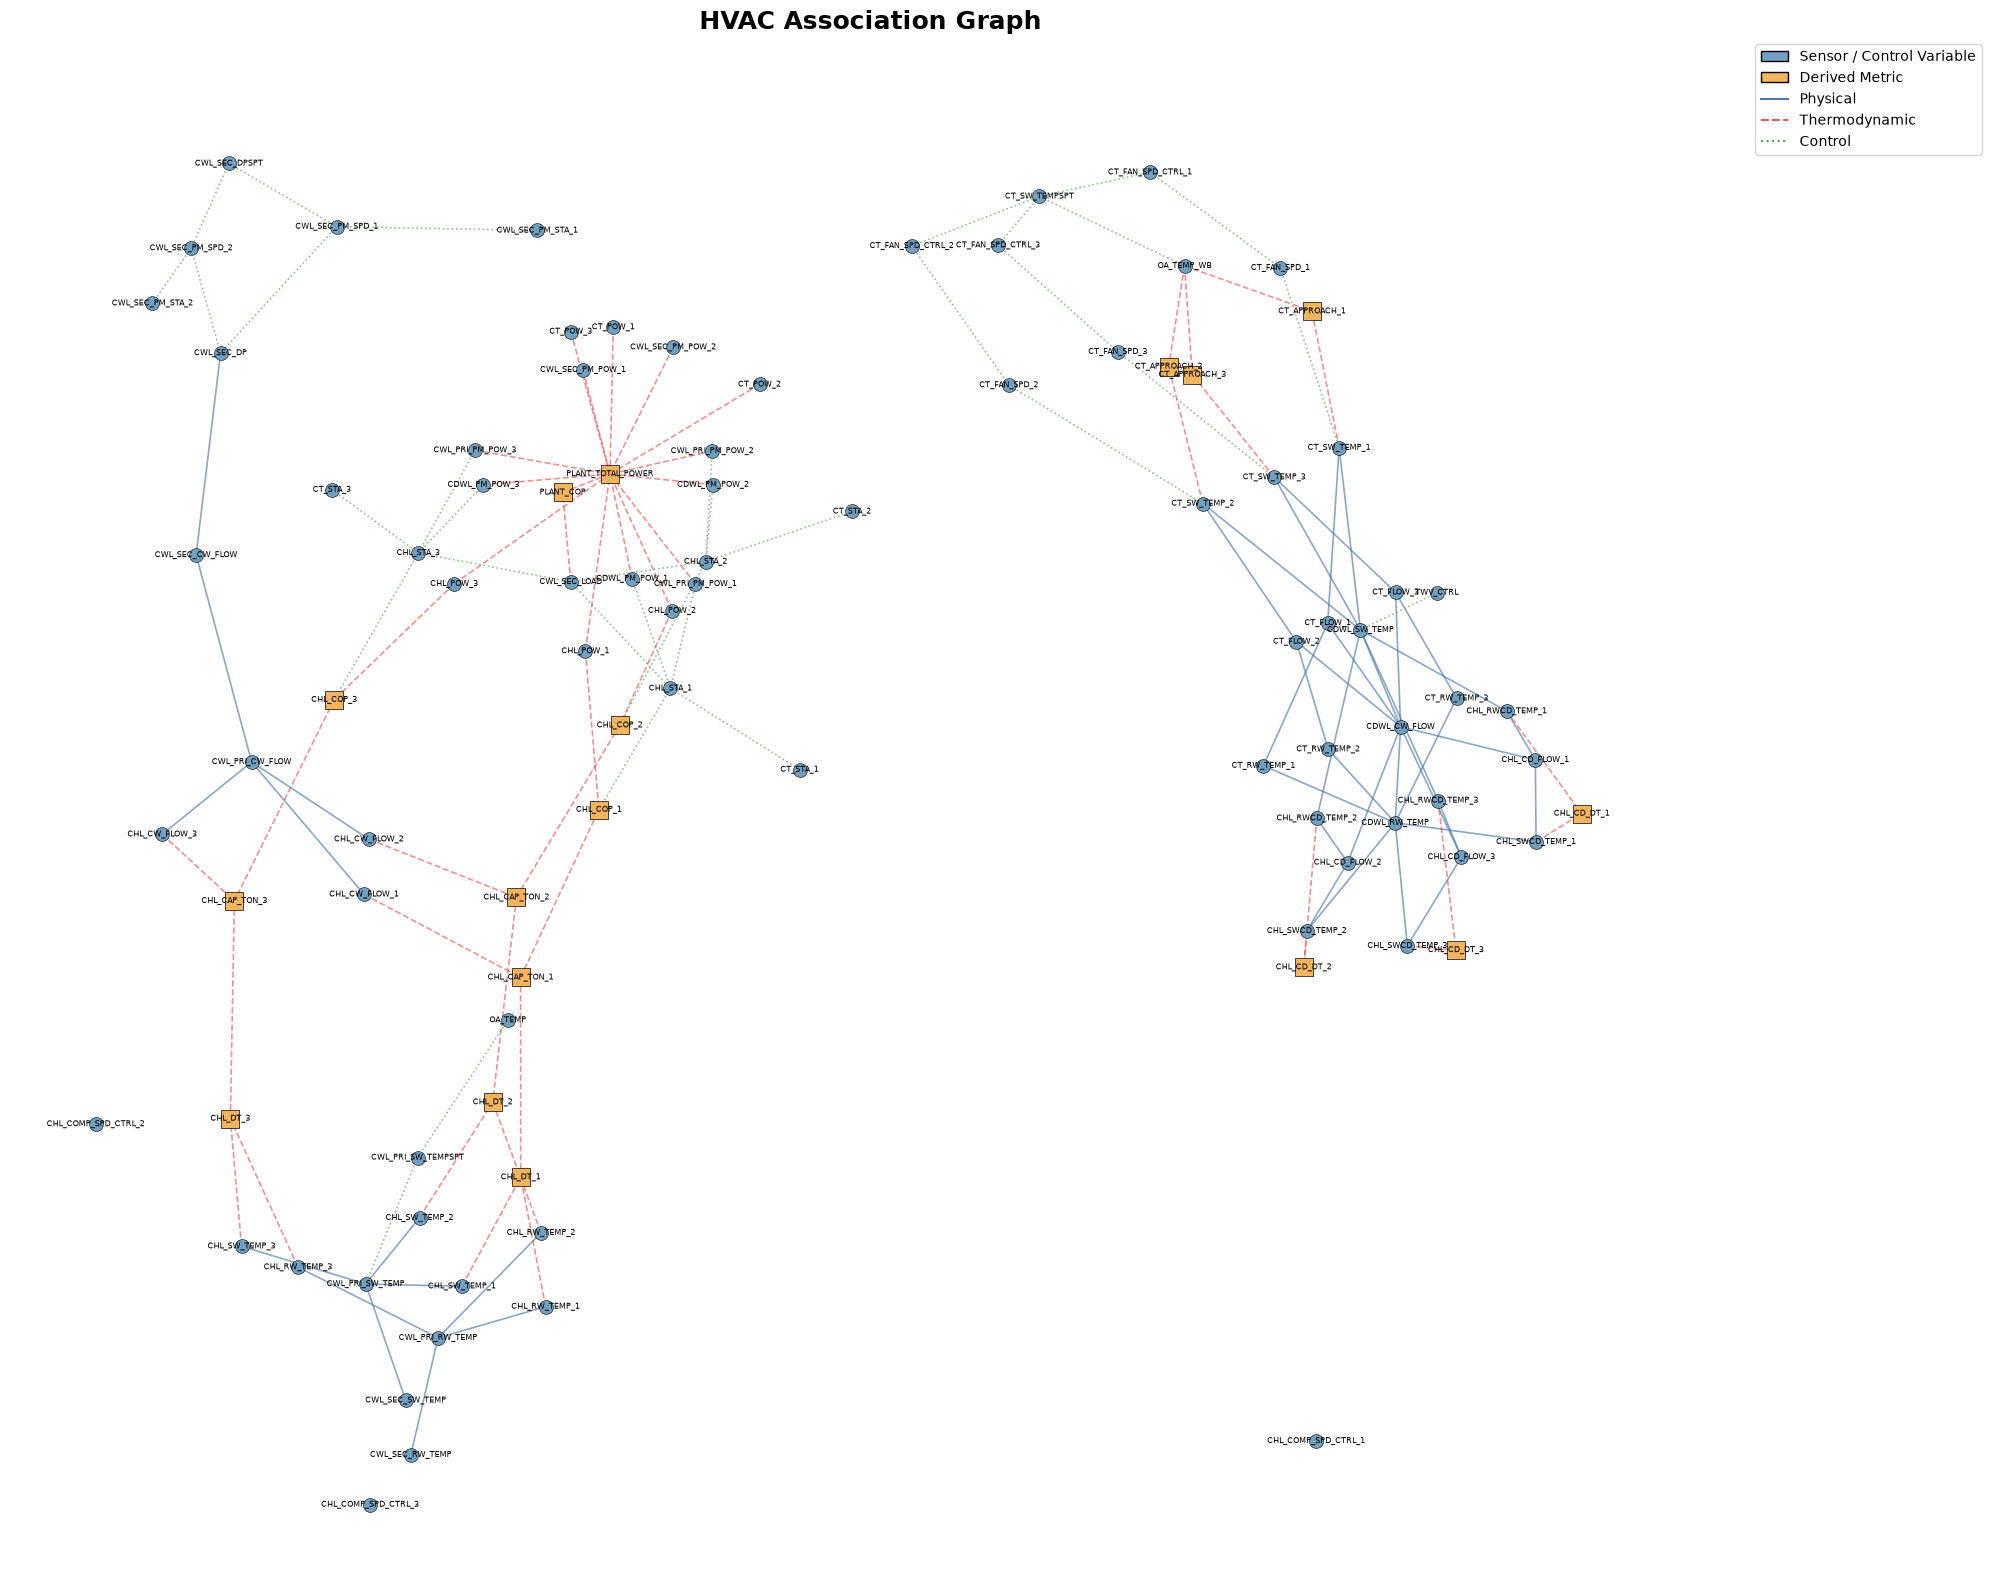

Figure saved to: outputs\hvac_association_graph.png
Connected components: 5
Isolated nodes: ['CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3']


In [41]:

import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# 1. Create a simple graph for visualization.
# The original MultiGraph remains unchanged.
layout_graph = nx.Graph()
layout_graph.add_nodes_from(G_built.nodes())
layout_graph.add_edges_from(G_built.edges())

# 2. Calculate node positions
pos = nx.spring_layout(
    layout_graph,
    seed=42,
    k=0.8,
    iterations=250
)

# 3. Separate node types
sensor_nodes = [
    n for n, d in G_built.nodes(data=True)
    if d["node_type"] == "sensor_or_control"
]

metric_nodes = [
    n for n, d in G_built.nodes(data=True)
    if d["node_type"] == "derived_metric"
]

# 4. Define edge styles
edge_styles = {
    "physical": {
        "color": "#4C78A8",
        "style": "solid"
    },
    "thermodynamic": {
        "color": "#E45756",
        "style": "dashed"
    },
    "control": {
        "color": "#54A24B",
        "style": "dotted"
    }
}

fig, ax = plt.subplots(figsize=(20, 16))

# 5. Draw each edge type separately
for edge_type, style in edge_styles.items():

    edges = [
        (u, v)
        for u, v, data in G_built.edges(data=True)
        if data["edge_type"] == edge_type
    ]

    nx.draw_networkx_edges(
        layout_graph,
        pos,
        edgelist=edges,
        edge_color=style["color"],
        style=style["style"],
        width=1.2,
        alpha=0.65,
        ax=ax
    )

# 6. Draw sensor/control nodes
nx.draw_networkx_nodes(
    G_built,
    pos,
    nodelist=sensor_nodes,
    node_color="#72A0C1",
    node_size=100,
    edgecolors="black",
    linewidths=0.4,
    ax=ax
)

# 7. Draw derived metric nodes
nx.draw_networkx_nodes(
    G_built,
    pos,
    nodelist=metric_nodes,
    node_color="#F2B45F",
    node_shape="s",
    node_size=150,
    edgecolors="black",
    linewidths=0.5,
    ax=ax
)

# 8. Draw node labels
nx.draw_networkx_labels(
    G_built,
    pos,
    font_size=6,
    font_weight="normal",
    ax=ax
)

# 9. Create legend
legend_items = [
    Patch(facecolor="#72A0C1", edgecolor="black",
          label="Sensor / Control Variable"),
    Patch(facecolor="#F2B45F", edgecolor="black",
          label="Derived Metric"),
    Line2D([0], [0], color="#4C78A8",
           linestyle="solid", label="Physical"),
    Line2D([0], [0], color="#E45756",
           linestyle="dashed", label="Thermodynamic"),
    Line2D([0], [0], color="#54A24B",
           linestyle="dotted", label="Control")
]

ax.legend(handles=legend_items, loc="upper left",
          bbox_to_anchor=(1.01, 1), fontsize=10)

ax.set_title(
    "HVAC Association Graph",
    fontsize=18,
    fontweight="bold"
)

ax.axis("off")
plt.tight_layout()

# 10. Save the figure
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

figure_path = output_dir / "hvac_association_graph.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)
print("Connected components:", nx.number_connected_components(G_built))
print("Isolated nodes:", list(nx.isolates(G_built)))


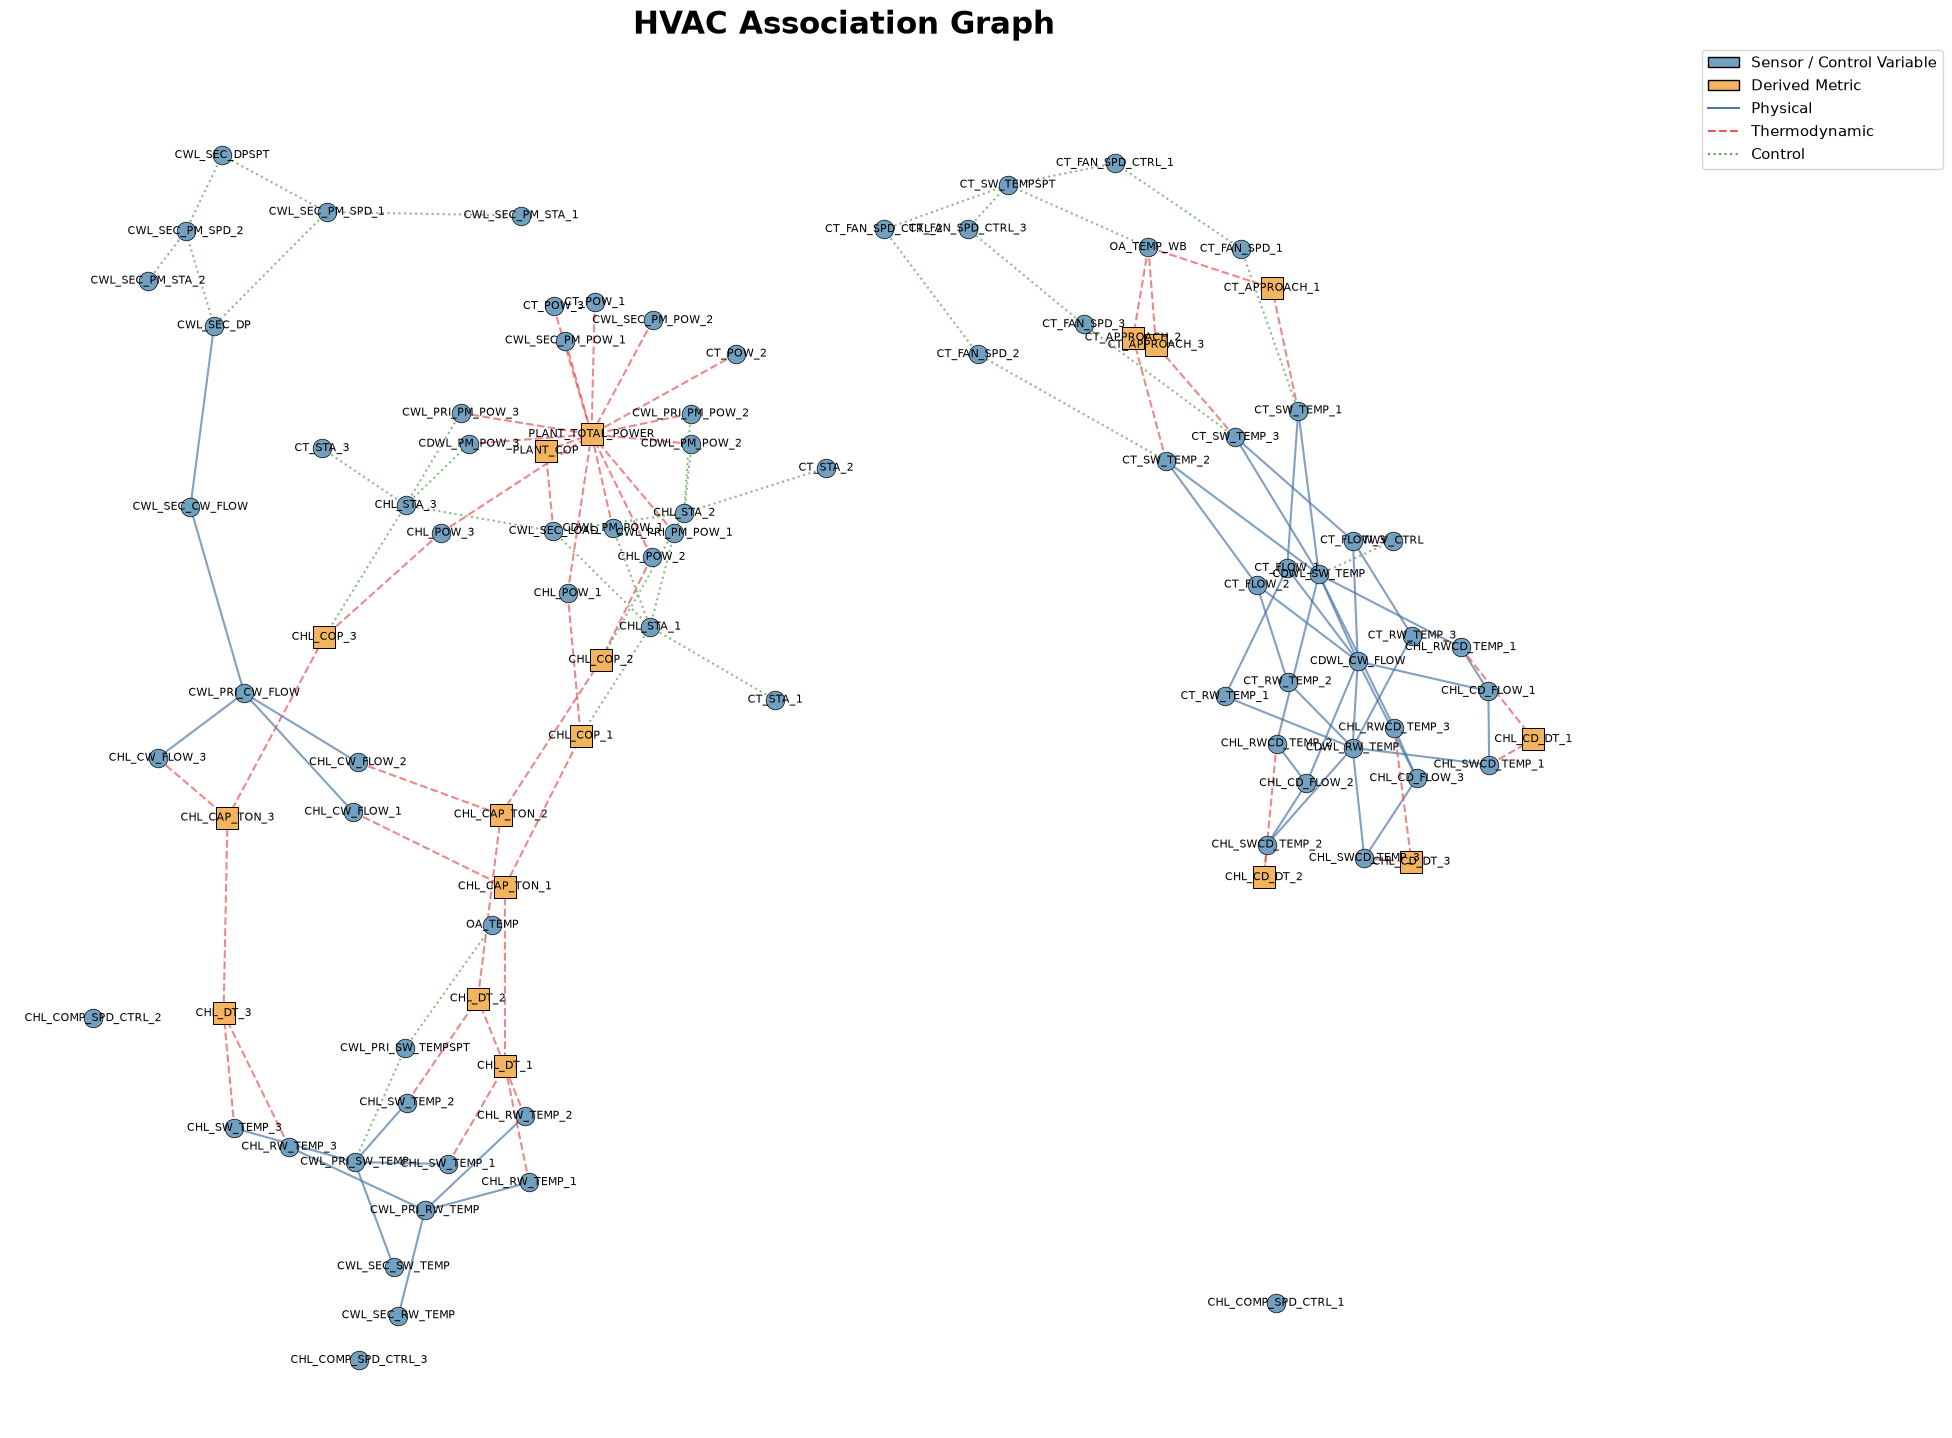

Connected components: 5
Isolated nodes: ['CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3']


In [42]:

# Reuse the graph and positions already created
fig, ax = plt.subplots(figsize=(24, 18))

# Leave room on the right for the legend
fig.subplots_adjust(right=0.82)

for edge_type, style in edge_styles.items():
    edges = [
        (u, v)
        for u, v, data in G_built.edges(data=True)
        if data["edge_type"] == edge_type
    ]

    nx.draw_networkx_edges(
        layout_graph, pos,
        edgelist=edges,
        edge_color=style["color"],
        style=style["style"],
        width=1.5,
        alpha=0.7,
        ax=ax
    )

nx.draw_networkx_nodes(
    G_built, pos,
    nodelist=sensor_nodes,
    node_color="#72A0C1",
    node_size=180,
    edgecolors="black",
    linewidths=0.5,
    ax=ax
)

nx.draw_networkx_nodes(
    G_built, pos,
    nodelist=metric_nodes,
    node_color="#F2B45F",
    node_shape="s",
    node_size=260,
    edgecolors="black",
    linewidths=0.7,
    ax=ax
)

nx.draw_networkx_labels(
    G_built, pos,
    font_size=8,
    ax=ax
)

ax.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=11,
    frameon=True
)

ax.set_title(
    "HVAC Association Graph",
    fontsize=22,
    fontweight="bold"
)

ax.axis("off")

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# High-resolution image
plt.savefig(
    output_dir / "hvac_association_graph.png",
    dpi=400,
    bbox_inches="tight"
)

# Vector format: excellent for zooming and research papers
plt.savefig(
    output_dir / "hvac_association_graph.svg",
    bbox_inches="tight"
)

plt.show()

print("Connected components:",
      nx.number_connected_components(G_built))

print("Isolated nodes:", list(nx.isolates(G_built)))


In [43]:
fig.subplots_adjust(right=0.78)

fig.legend(
    handles=legend_items,
    loc="center left",
    bbox_to_anchor=(0.80, 0.5),
    fontsize=11,
    frameon=True
)

In [44]:
print("ADDITIONAL PHYSICAL EDGES TO REVIEW")
print("=" * 55)

for i, (source, target) in enumerate(
    additional_physical_edges, start=1
):
    print(f"{i:02}. {source}  <-->  {target}")

ADDITIONAL PHYSICAL EDGES TO REVIEW
01. CHL_CD_FLOW_1  <-->  CHL_SWCD_TEMP_1
02. CHL_CD_FLOW_1  <-->  CHL_RWCD_TEMP_1
03. CHL_CD_FLOW_2  <-->  CHL_SWCD_TEMP_2
04. CHL_CD_FLOW_2  <-->  CHL_RWCD_TEMP_2
05. CHL_CD_FLOW_3  <-->  CHL_SWCD_TEMP_3
06. CHL_CD_FLOW_3  <-->  CHL_RWCD_TEMP_3
07. CT_FLOW_1  <-->  CT_SW_TEMP_1
08. CT_FLOW_1  <-->  CT_RW_TEMP_1
09. CT_FLOW_2  <-->  CT_SW_TEMP_2
10. CT_FLOW_2  <-->  CT_RW_TEMP_2
11. CT_FLOW_3  <-->  CT_SW_TEMP_3
12. CT_FLOW_3  <-->  CT_RW_TEMP_3
13. CDWL_CW_FLOW  <-->  CDWL_SW_TEMP
14. CDWL_CW_FLOW  <-->  CDWL_RW_TEMP
15. CWL_SEC_DP  <-->  CWL_SEC_CW_FLOW


In [45]:
additional_physical_edges = []

# A. Chiller condenser-water circuit
for i in range(1, 4):
    additional_physical_edges.extend([
        (f"CHL_CD_FLOW_{i}", f"CHL_SWCD_TEMP_{i}"),
        (f"CHL_CD_FLOW_{i}", f"CHL_RWCD_TEMP_{i}")
    ])

# B. Cooling tower water circuits
for i in range(1, 4):
    additional_physical_edges.extend([
        (f"CT_FLOW_{i}", f"CT_SW_TEMP_{i}"),
        (f"CT_FLOW_{i}", f"CT_RW_TEMP_{i}")
    ])

# C. Common condenser-water loop
additional_physical_edges.extend([
    ("CDWL_CW_FLOW", "CDWL_SW_TEMP"),
    ("CDWL_CW_FLOW", "CDWL_RW_TEMP")
])

# D. Secondary chilled-water loop
additional_physical_edges.append(
    ("CWL_SEC_DP", "CWL_SEC_CW_FLOW")
)

In [46]:

import networkx as nx
from collections import Counter

# 1. Connected components
components = sorted(
    nx.connected_components(G_built),
    key=len,
    reverse=True
)

# 2. Edge counts
edge_counts = Counter(
    data["edge_type"]
    for _, _, data in G_built.edges(data=True)
)

# 3. Allowed pairs
pair_counts = {
    k: len(graph_module.allowed_pairs(G_built, k))
    for k in [1, 2, 3]
}

# 4. Isolated nodes
isolated_nodes = list(nx.isolates(G_built))

# 5. Print final report
print("=" * 45)
print("FINAL HVAC GRAPH VALIDATION")
print("=" * 45)

print("Nodes:", G_built.number_of_nodes())
print("Edges:", G_built.number_of_edges())

print("\nEdge types:")
for edge_type, count in edge_counts.items():
    print(f"{edge_type}: {count}")

print("\nConnected components:", len(components))
print("Component sizes:", [len(c) for c in components])

print("\nIsolated nodes:", isolated_nodes)

print("\nAllowed variable pairs:")
for k, count in pair_counts.items():
    print(f"k={k}: {count}")

print("\nAll graph functions completed successfully.")


FINAL HVAC GRAPH VALIDATION
Nodes: 94
Edges: 125

Edge types:
thermodynamic: 46
control: 34
physical: 45

Connected components: 5
Component sizes: [55, 36, 1, 1, 1]

Isolated nodes: ['CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3']

Allowed variable pairs:
k=1: 125
k=2: 466
k=3: 859

All graph functions completed successfully.
